In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib import patches as mpatches
from hyperparameter_search import HYPERPARAMETER_GROUPS
from utils import AUX_HEAD_KEYS
from tqdm import tqdm
import math

In [5]:
def increase_brightness(color: str | tuple[float, float, float], factor: float):
    if isinstance(color, str):
        r = int(color[1:3], 16)
        g = int(color[3:5], 16)
        b = int(color[5:7], 16)
    else:
        # seaborn/matplotlib tuples are floats in 0-1
        r, g, b = (int(round(c * 255)) for c in color)

    factor = min(max(factor, 0.0), 1.0)
    r = int(r + (255 - r) * factor)
    g = int(g + (255 - g) * factor)
    b = int(b + (255 - b) * factor)
    return f"#{r:02x}{g:02x}{b:02x}"

In [6]:
data = pd.read_csv("results/aux_head_regression_scores.csv")
data["run_number"] = data["model_name"].str[-1].astype(int)
data["model_name"] = data["model_name"].str[:-3]
data["aux_weight"] = data["model_name"].str.extract(r"_w([\d\.]+)$").astype(float)
data["model_name"] = data["model_name"].str.replace(r"_w[\d\.]+$", "", regex=True)
data["readable_name"] = data["model_name"] + data["aux_weight"].map(lambda x: f" Weight={x}" if x > 0 else "")
data

,model_name,target,iteration,r2_score,mae,target_stddev,run_number,aux_weight,readable_name
0,angular_velocity_y,velocity_forward,0,0.480349,0.183559,0.592117,2,0.1,angular_velocity_y Weight=0.1
1,angular_velocity_y,velocity_lateral,0,0.864162,0.018511,0.066221,2,0.1,angular_velocity_y Weight=0.1
2,angular_velocity_y,track_curvature_0_50,0,0.265886,0.276100,0.466201,2,0.1,angular_velocity_y Weight=0.1
3,angular_velocity_y,track_curvature_1_00,0,0.199226,0.290405,0.462444,2,0.1,angular_velocity_y Weight=0.1
4,angular_velocity_y,track_curvature_1_50,0,0.046198,0.322317,0.468267,2,0.1,angular_velocity_y Weight=0.1
...,...,...,...,...,...,...,...,...,...
60097,baseline,wheel_slip_forward_front_right,600,0.079978,0.047037,0.099006,6,0.0,baseline
60098,baseline,wheel_slip_lateral_front_right,600,0.839062,0.004491,0.017453,6,0.0,baseline
60099,baseline,wheel_slip_forward_back_right,600,0.089675,0.047405,0.100029,6,0.0,baseline
60100,baseline,wheel_slip_lateral_back_right,600,0.543212,0.002068,0.005463,6,0.0,baseline


In [7]:
baseline = (
    data[data["model_name"] == "baseline"]
    .groupby(["iteration", "target"])["r2_score"]
    .agg(["mean", "std"])
    .reset_index()
)
final_it = baseline["iteration"].max()

baseline_data = data[data["model_name"] == "baseline"].groupby(["model_name", "iteration", "target"]).agg({"r2_score": ["mean", "std"]}).reset_index()
baseline_data[baseline_data["iteration"].isin([0, 100, 200, 300, 400, 500, 599])].pivot_table(
    index="target",
    columns="iteration",
    values="r2_score"
)

/var/folders/tf/2rc426jn0wdfbl876c7ypg1h0000gn/T/ipykernel_37103/399708235.py:10: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  baseline_data[baseline_data["iteration"].isin([0, 100, 200, 300, 400, 500, 599])].pivot_table(


mean                                \
iteration                            0         100       200       300   
target                                                                   
angular_velocity_y              0.912588  0.787812  0.770280  0.794310   
track_curvature_0_50            0.263599  0.302691  0.287146  0.228200   
track_curvature_1_00            0.180776  0.295380  0.290578  0.209903   
track_curvature_1_50            0.014406  0.258853  0.208461  0.220379   
track_curvature_2_00           -0.067264  0.218624  0.168359  0.170596   
track_curvature_2_50           -0.104013  0.094237  0.081421  0.077798   
track_curvature_3_00           -0.086801  0.005106  0.005458  0.014060   
track_curvature_3_50           -0.079935 -0.018365 -0.019474 -0.055791   
track_curvature_4_00           -0.079181 -0.034670 -0.031965 -0.037559   
track_curvature_4_50           -0.068232 -0.041570 -0.043869 -0.023852   
track_curvature_5_00           -0.076667 -0.055460 -0.051282 -0.066090   
track_curvature_5_50           -0.082095 -0.081618 -0.074279 -0.081186   
track_curvature_6_00           -0.101668 -0.118547 -0.107605 -0.117565   
track_curvature_6_50           -0.088225 -0.064726 -0.054895 -0.048301   
track_curvature_7_00           -0.090104 -0.078343 -0.076543 -0.075473   
track_curvature_7_50           -0.076961 -0.058292 -0.075025 -0.043245   
track_curvature_8_00           -0.077421 -0.062195 -0.062795 -0.045804   
velocity_forward                0.508870  0.416119  0.471017  0.394796   
velocity_lateral                0.885397  0.796653  0.766573  0.806878   
wheel_slip_forward_back_left    0.080622  0.035590  0.118525  0.134394   
wheel_slip_forward_back_right   0.148179  0.034215  0.112988  0.138913   
wheel_slip_forward_front_left   0.081592  0.039694  0.119899  0.137041   
wheel_slip_forward_front_right  0.132435  0.029122  0.106054  0.131611   
wheel_slip_lateral_back_left    0.666156  0.587240  0.541075  0.523543   
wheel_slip_lateral_back_right   0.675616  0.591833  0.553145  0.541990   
wheel_slip_lateral_front_left   0.813322  0.664976  0.688515  0.739775   
wheel_slip_lateral_front_right  0.831825  0.702294  0.721220  0.770535   

                                                         std            \
iteration                            400       500       0         100   
target                                                                   
angular_velocity_y              0.801146  0.780717  0.017417  0.028817   
track_curvature_0_50            0.339538  0.288514  0.027095  0.030796   
track_curvature_1_00            0.283590  0.298499  0.035982  0.058328   
track_curvature_1_50            0.219187  0.238978  0.038628  0.064018   
track_curvature_2_00            0.215751  0.238106  0.051592  0.052331   
track_curvature_2_50            0.104966  0.151061  0.022942  0.057905   
track_curvature_3_00            0.037159  0.061636  0.024177  0.066215   
track_curvature_3_50            0.019294  0.021965  0.042074  0.067534   
track_curvature_4_00            0.010388 -0.001620  0.046071  0.061418   
track_curvature_4_50            0.010751 -0.011531  0.044665  0.057665   
track_curvature_5_00           -0.019409 -0.018873  0.034607  0.045778   
track_curvature_5_50           -0.056494 -0.042104  0.019944  0.034975   
track_curvature_6_00           -0.080512 -0.096095  0.021118  0.051829   
track_curvature_6_50           -0.034632 -0.043251  0.019178  0.028113   
track_curvature_7_00           -0.094812 -0.081191  0.027336  0.046137   
track_curvature_7_50           -0.040368 -0.041955  0.024313  0.026732   
track_curvature_8_00           -0.044940 -0.034144  0.025070  0.025107   
velocity_forward                0.499984  0.590143  0.016702  0.074286   
velocity_lateral                0.809426  0.784450  0.022082  0.032803   
wheel_slip_forward_back_left    0.162697  0.166566  0.041437  0.063876   
wheel_slip_forward_back_right   0.131431  0.118707  0.039653  0.065506   
wheel_slip_forward_front_left   0.16538

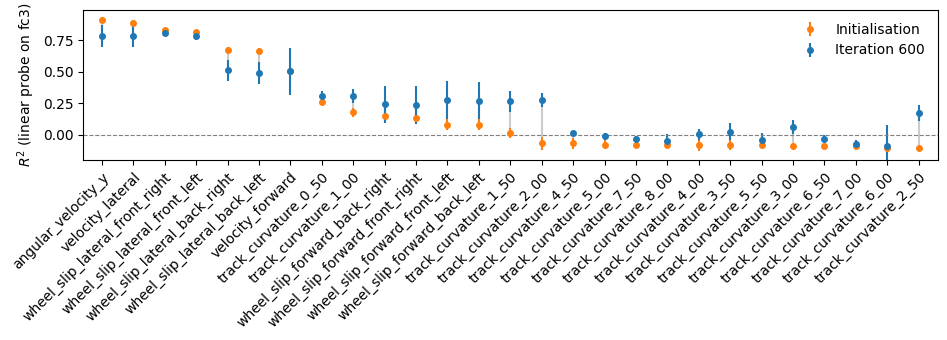

In [8]:
start = baseline[baseline.iteration == 0].set_index("target")
end = baseline[baseline.iteration == final_it].set_index("target")
order = start["mean"].sort_values(ascending=False).index   # left = highest at init
start, end = start.loc[order], end.loc[order]
x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(0.3 * len(order) + 1.5, 3.5))
ax.vlines(x, start["mean"], end["mean"], color="0.8", zorder=1)
ax.errorbar(x, start["mean"], yerr=start["std"], fmt="o", ms=4,
            color="tab:orange", label="Initialisation", capsize=0)
ax.errorbar(x, end["mean"], yerr=end["std"], fmt="o", ms=4,
            color="tab:blue", label=f"Iteration {final_it}", capsize=0)
ax.set_xticks(x, order, rotation=45, ha="right", rotation_mode="anchor")
ax.set_xlim(-0.6, len(order) - 0.4)
ax.set_ylabel(r"$R^2$ (linear probe on fc3)")
ax.set_ylim(bottom=max(-0.2, ax.get_ylim()[0]))            # clip very negative R²
ax.axhline(0, color="0.5", lw=0.8, ls="--")
ax.legend(loc="upper right", frameon=False)
fig.tight_layout()
fig.savefig("results/figures/probe_dumbbell.pdf")

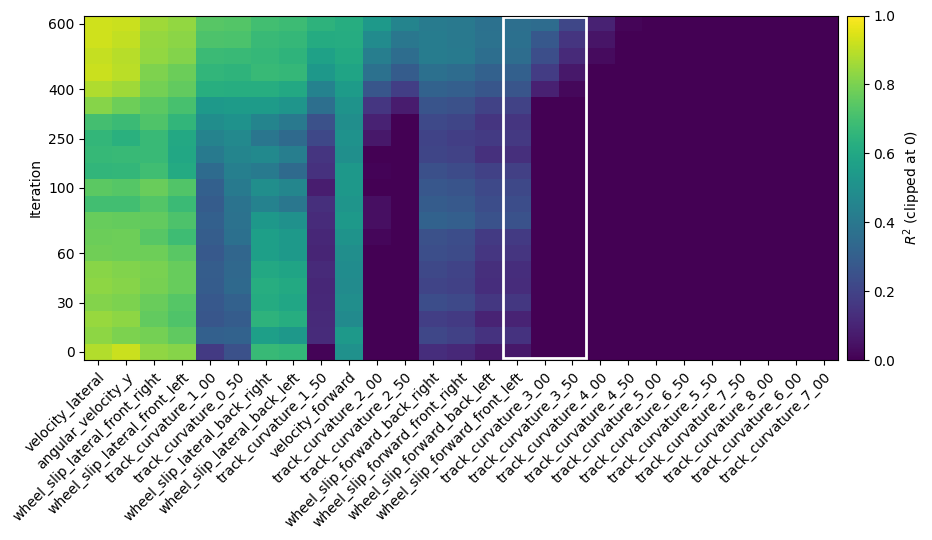

In [9]:
mean = (
    data[(data["model_name"] == "all") & (data["aux_weight"] == 1.0)]
    .groupby(["iteration", "target"])["r2_score"]
    .agg(["mean", "std"])
    .reset_index()
).pivot(index="target", columns="iteration", values="mean")
mean = mean.loc[mean[final_it].sort_values(ascending=False).index]
# rows = iterations, cols = targets
mat = mean.clip(lower=0).T

fig, ax = plt.subplots(figsize=(0.3 * len(mean) + 2, 5.5))
im = ax.imshow(mat, aspect="auto", cmap="viridis", vmin=0, vmax=1,
               interpolation="nearest", origin="lower")

rect = mpatches.Rectangle((14.5, -0.4), 3, 20.8,
                          linewidth=2, edgecolor='w', facecolor='none')
ax.add_patch(rect)

ticks = np.linspace(0, mat.shape[0] - 1, 7).astype(int)
ax.set_yticks(ticks, mat.index[ticks])
ax.set_xticks(range(mat.shape[1]), mat.columns,
              rotation=45, ha="right", rotation_mode="anchor")
ax.set_ylabel("Iteration")
fig.colorbar(im, ax=ax, label=r"$R^2$ (clipped at 0)", pad=0.01)
fig.tight_layout()
fig.savefig("results/figures/probe_heatmap.pdf")

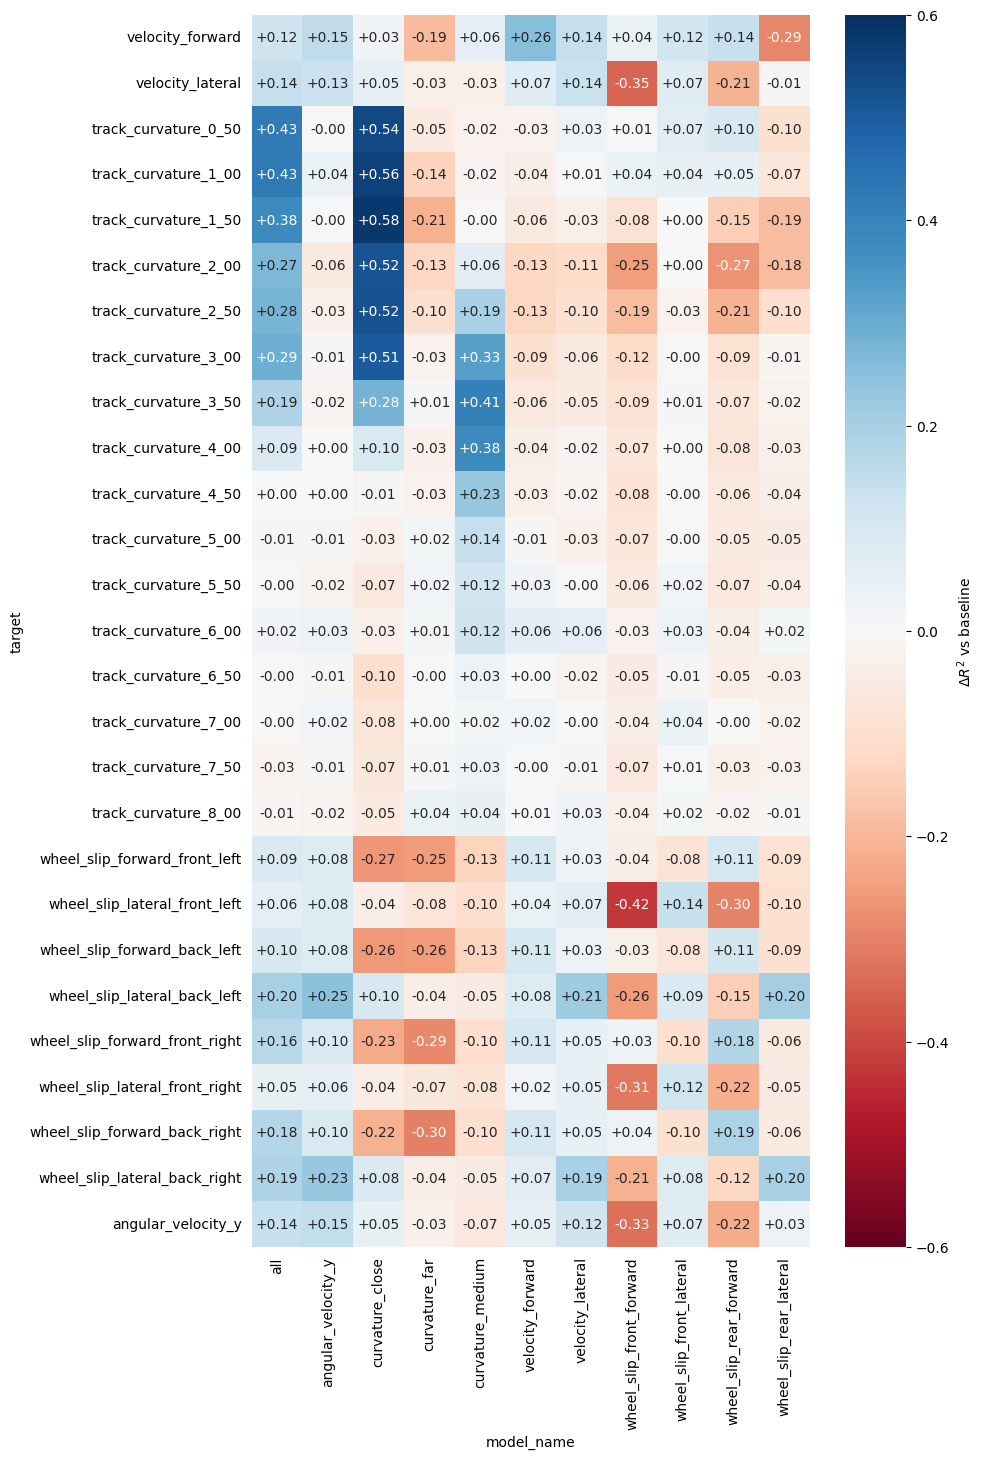

In [10]:
aux_weight = 1.0

pivot = (
    data[((data["aux_weight"] == aux_weight) | (data["model_name"] == "baseline"))
         & (data["iteration"] == 600)]
    .groupby(["model_name", "target"])["r2_score"]
    .mean()
    .unstack("target")
    .reindex(columns=AUX_HEAD_KEYS)
)

delta = pivot.sub(pivot.loc["baseline"], axis="columns").drop(index="baseline")

plt.figure(figsize=(9, 16))
sns.heatmap(
    delta.T,
    cmap="RdBu",
    center=0,
    vmin=-0.6, vmax=0.6,
    cbar_kws={"label": r"$\Delta R^2$ vs baseline"},
    annot=True,
    fmt="+.2f"
).tick_params(left=False, bottom=False)
plt.savefig("results/figures/probe_heatmap_delta_vs_baseline.pdf", bbox_inches='tight')


In [12]:
pivot.sub(pivot.loc["baseline"]).loc["curvature_close"]

target
velocity_forward                  0.026702
velocity_lateral                  0.054368
track_curvature_0_50              0.539592
track_curvature_1_00              0.558789
track_curvature_1_50              0.579604
track_curvature_2_00              0.519848
track_curvature_2_50              0.523145
track_curvature_3_00              0.505357
track_curvature_3_50              0.284468
track_curvature_4_00              0.096027
track_curvature_4_50             -0.006177
track_curvature_5_00             -0.032030
track_curvature_5_50             -0.065279
track_curvature_6_00             -0.034614
track_curvature_6_50             -0.099614
track_curvature_7_00             -0.077476
track_curvature_7_50             -0.067514
track_curvature_8_00             -0.052527
wheel_slip_forward_front_left    -0.266586
wheel_slip_lateral_front_left    -0.041605
wheel_slip_forward_back_left     -0.261380
wheel_slip_lateral_back_left      0.100031
wheel_slip_forward_front_right   -0.226443
whee